<a href="https://colab.research.google.com/github/TWAPZCODE/Quant-Research/blob/main/MovingAverage_trendfollowing_Backtester.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Moving Average Trend-Following Backtester — NQ **Futures**

In [158]:
#Import Libraries
from datetime import datetime
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [159]:
## Define Variables for user configuration
starting_balance = 1000
ma = 20

#Daily Data
start = datetime(2015, 1, 1)
end = datetime(2025, 1, 1)
ticker = "NQ=F"
interval = "1d"

In [160]:
price = yf.download(ticker, start=start, end=end, interval=interval, multi_level_index=False, auto_adjust=True)

price

[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,4214.25,4272.75,4201.00,4240.25,229555
2015-01-05,4161.75,4220.75,4145.00,4216.00,313771
2015-01-06,4102.25,4172.50,4082.00,4166.50,426154
2015-01-07,4151.50,4163.25,4102.75,4105.50,328184
2015-01-08,4232.25,4242.75,4152.25,4152.25,272056
...,...,...,...,...,...
2024-12-24,22028.50,22049.75,21709.00,21743.25,261201
2024-12-26,22008.00,22111.25,21870.25,22049.50,407116
2024-12-27,21698.50,22008.00,21498.75,21990.75,572604


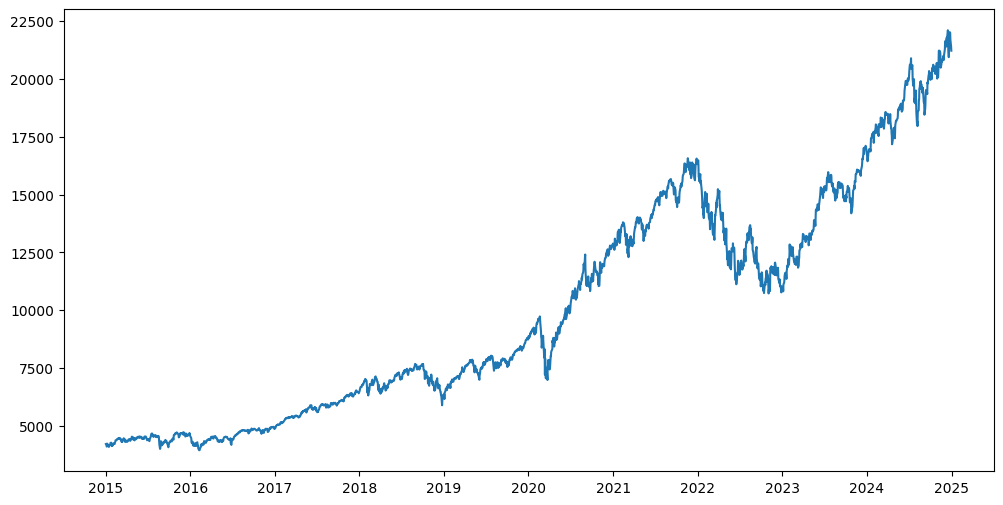

In [161]:
# Visualising Data
plt.figure(figsize=(12,6))
plt.plot(price['Close'])
plt.show()

In [162]:
# Calculate daily returns
price['Return'] = price.Close / price.Close.shift(1)
price.Return.iat[0] = 1
price['Bench_Bal'] = starting_balance *price.Return.cumprod()

price

,Close,High,Low,Open,Volume,Return,Bench_Bal
Date,,,,,,,
2015-01-02,4214.25,4272.75,4201.00,4240.25,229555,1.000000,1000.000000
2015-01-05,4161.75,4220.75,4145.00,4216.00,313771,0.987542,987.542267
2015-01-06,4102.25,4172.50,4082.00,4166.50,426154,0.985703,973.423504
2015-01-07,4151.50,4163.25,4102.75,4105.50,328184,1.012006,985.110043
2015-01-08,4232.25,4242.75,4152.25,4152.25,272056,1.019451,1004.271223
...,...,...,...,...,...,...,...
2024-12-24,22028.50,22049.75,21709.00,21743.25,261201,1.012653,5227.145993
2024-12-26,22008.00,22111.25,21870.25,22049.50,407116,0.999069,5222.281545
2024-12-27,21698.50,22008.00,21498.75,21990.75,572604,0.985937,5148.840244


In [163]:
first_timestamp = price.index.min()
last_timestamp = price.index.max()

# Calculate the number of years
years = ( last_timestamp - first_timestamp).days / 365.25

price['Bench_Peak']= price.Bench_Bal.cummax()
price['Bench_DD'] = price.Bench_Bal - price.Bench_Peak

cagr_bench = round((((price.Bench_Bal.iloc[-1] / price.Bench_Bal.iloc[0]) ** (1/years)) - 1) * 100, 2)
dd_bench = round(((price.Bench_DD / price.Bench_Peak).min()) * 100, 2)

print(f"Benchmark Annual Return: {cagr_bench}%")
print(f"Benchmark DD: {dd_bench}%")

Benchmark Annual Return: 17.56%
Benchmark DD: -35.28%


In [164]:
# Calculate indicators
price['MA'] = price.Close.rolling(window=ma).mean()

price['Long'] = price.Close > price.MA
price['Short'] = price.Close < price.MA

price

,Close,High,Low,Open,Volume,Return,Bench_Bal,Bench_Peak,Bench_DD,MA,Long,Short
Date,,,,,,,,,,,,
2015-01-02,4214.25,4272.75,4201.00,4240.25,229555,1.000000,1000.000000,1000.000000,0.000000,NaN,False,False
2015-01-05,4161.75,4220.75,4145.00,4216.00,313771,0.987542,987.542267,1000.000000,-12.457733,NaN,False,False
2015-01-06,4102.25,4172.50,4082.00,4166.50,426154,0.985703,973.423504,1000.000000,-26.576496,NaN,False,False
2015-01-07,4151.50,4163.25,4102.75,4105.50,328184,1.012006,985.110043,1000.000000,-14.889957,NaN,False,False
2015-01-08,4232.25,4242.75,4152.25,4152.25,272056,1.019451,1004.271223,1004.271223,0.000000,NaN,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,22028.50,22049.75,21709.00,21743.25,261201,1.012653,5227.145993,5246.544462,-19.398469,21464.086523,True,False
2024-12-26,22008.00,22111.25,21870.25,22049.50,407116,0.999069,5222.281545,5246.544462,-24.262917,21514.811523,True,False
2024-12-27,21698.50,22008.00,21498.75,21990.75,572604,0.985937,5148.840244,5246.544462,-97.704218,21559.086523,True,False


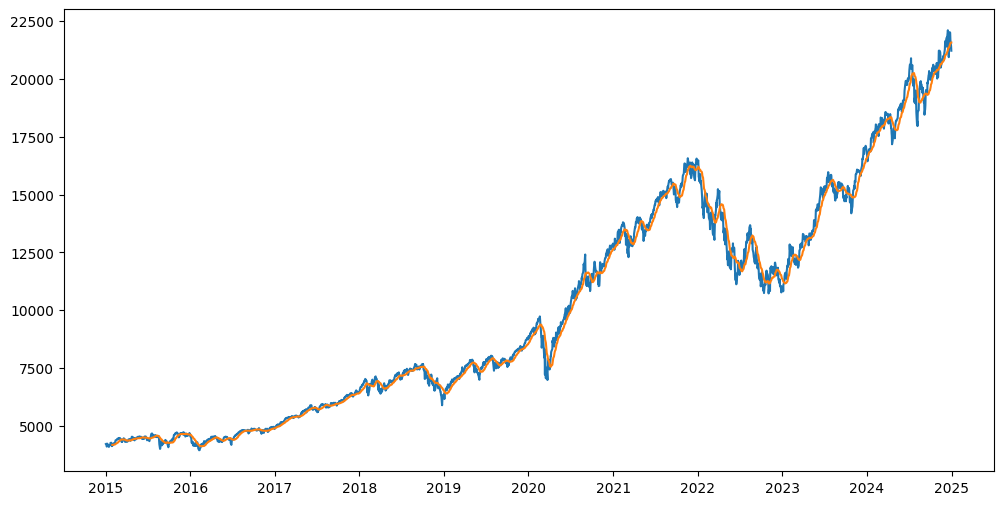

In [165]:
plt.figure(figsize=(12,6))
plt.plot(price.Close)
plt.plot(price.MA)

In [166]:
price['Sys_Ret'] = np.where(price.Long.shift(1), price.Return, np.where(price.Short.shift(1), 2 - price.Return, 1))

price['Sys_Bal'] = starting_balance * price.Sys_Ret.cumprod()

price

,Close,High,Low,Open,Volume,Return,Bench_Bal,Bench_Peak,Bench_DD,MA,Long,Short,Sys_Ret,Sys_Bal
Date,,,,,,,,,,,,,,
2015-01-02,4214.25,4272.75,4201.00,4240.25,229555,1.000000,1000.000000,1000.000000,0.000000,NaN,False,False,1.000000,1000.000000
2015-01-05,4161.75,4220.75,4145.00,4216.00,313771,0.987542,987.542267,1000.000000,-12.457733,NaN,False,False,1.000000,1000.000000
2015-01-06,4102.25,4172.50,4082.00,4166.50,426154,0.985703,973.423504,1000.000000,-26.576496,NaN,False,False,1.000000,1000.000000
2015-01-07,4151.50,4163.25,4102.75,4105.50,328184,1.012006,985.110043,1000.000000,-14.889957,NaN,False,False,1.000000,1000.000000
2015-01-08,4232.25,4242.75,4152.25,4152.25,272056,1.019451,1004.271223,1004.271223,0.000000,NaN,False,False,1.000000,1000.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,22028.50,22049.75,21709.00,21743.25,261201,1.012653,5227.145993,5246.544462,-19.398469,21464.086523,True,False,1.012653,1549.549151
2024-12-26,22008.00,22111.25,21870.25,22049.50,407116,0.999069,5222.281545,5246.544462,-24.262917,21514.811523,True,False,0.999069,1548.107121
2024-12-27,21698.50,22008.00,21498.75,21990.75,572604,0.985937,5148.840244,5246.544462,-97.704218,21559.086523,True,False,0.985937,1526.335985


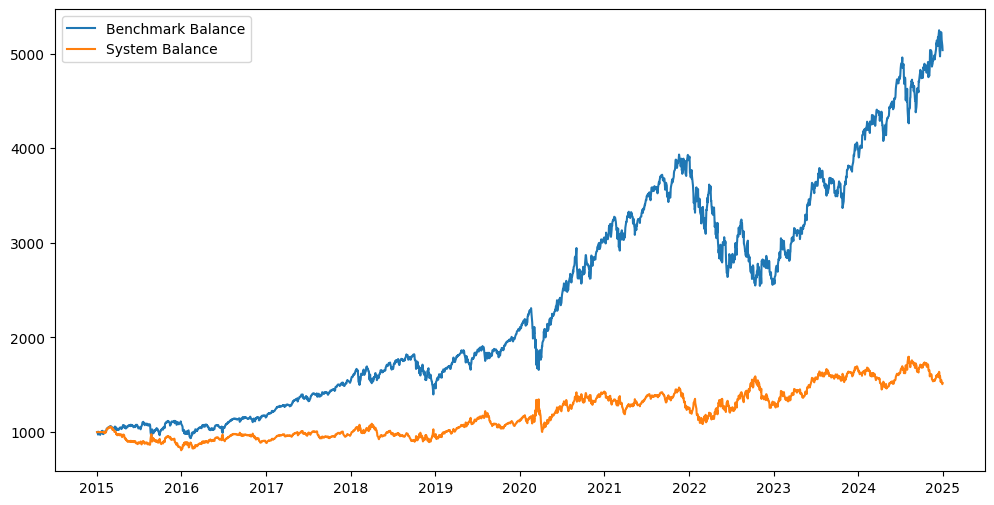

In [167]:
plt.figure(figsize=(12,6))
plt.plot(price.Bench_Bal, label="Benchmark Balance")
plt.plot(price.Sys_Bal, label="System Balance")

plt.legend()
plt.show()